In [1]:
import os
import sys; sys.path.append("..")
import numpy as np 
import matplotlib.pyplot as plt
import seaborn as sns
import math

from utils.plots import cross_validation_visualization
from utils.helpers import *
from implementations import ridge_regression
from utils.metrics import *

In [2]:
x_train, x_test, y_train, train_ids, test_ids = load_csv_data(data_path='../data/')

# 1. On preprocessed data 
## With arbitrary lambda

In [3]:
data_path = '../data/preprocessed'

x_train_preprocessed = np.load(os.path.join(data_path, 'x_train_preprocessed.npy'))
x_test_preprocessed  = np.load(os.path.join(data_path, 'x_test_preprocessed.npy'))

print("Loaded shapes:")
print("x_train:", x_train_preprocessed.shape)
print("x_test: ", x_test_preprocessed.shape)

Loaded shapes:
x_train: (328135, 174)
x_test:  (109379, 174)


In [4]:
w, mse = ridge_regression(y_train, x_train_preprocessed, lambda_= 0.1)

pred_train = x_train_preprocessed @ w 

print("Scores ridge regression preprocessed data: ")
print(f"Accuracy:   {compute_accuracy(y_train, pred_train):.4f}")
print(f"Precision:  {compute_precision(y_train, pred_train):.4f}")
print(f"Recall:     {compute_recall(y_train, pred_train):.4f}")
print(f"F1 Score:   {compute_f1(y_train, pred_train):.4f}")
print(f"R2 Score:   {compute_r2(y_train, pred_train):.4f}")

Scores ridge regression preprocessed data: 
Accuracy:   0.6493
Precision:  0.1885
Recall:     0.8988
F1 Score:   0.3116
R2 Score:   -1.9431


In [5]:
print("1. NaNs in x_train_preprocessed:", np.isnan(x_train_preprocessed).any())
print("2. NaNs in y_train:             ", np.isnan(y_train).any())
print("3. NaNs in weight vector w:     ", np.isnan(w).any())

1. NaNs in x_train_preprocessed: False
2. NaNs in y_train:              False
3. NaNs in weight vector w:      False


# 2. Computing optimal lambda: 
## Cross validation

The choice of lambda which leads to the best test rmse is 0.00115 with a test rmse of 0.973


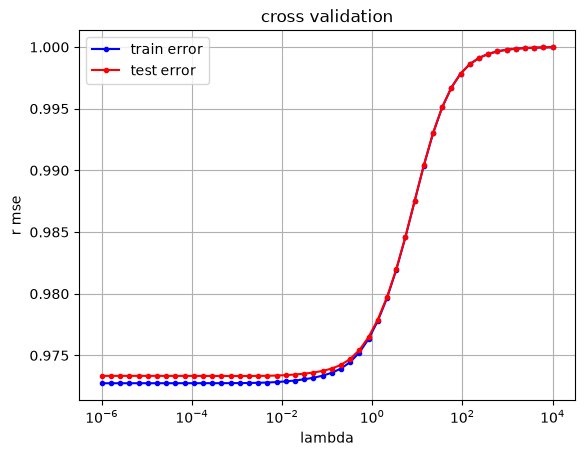

In [6]:
from utils.costs import mse


def build_k_indices(y, k_fold, seed):
    """Build k indices for k-fold CV."""
    num_row = y.shape[0]
    interval = int(num_row / k_fold)
    np.random.seed(seed)
    indices = np.random.permutation(num_row)
    k_indices = [
        indices[k * interval : (k + 1) * interval] for k in range(k_fold)
    ]
    return np.array(k_indices)


def cross_validation(y, x, k_indices, k, lambda_):
    """Return the test loss of ridge regression for fold k."""
    # Split fold indices
    te_indice = k_indices[k]
    tr_indice = k_indices[~(np.arange(k_indices.shape[0]) == k)].reshape(-1)

    y_te, y_tr = y[te_indice], y[tr_indice]
    x_te, x_tr = x[te_indice], x[tr_indice]

    # Fit Ridge Regression strictly on training fold
    w, _ = ridge_regression(y_tr, x_tr, lambda_)

    # Compute RMSE
    loss_tr = np.sqrt(2 * mse(y_tr - x_tr @ w))
    loss_te = np.sqrt(2 * mse(y_te - x_te @ w))

    return float(loss_tr), float(loss_te)

def cross_validation_demo(k_fold, lambdas):
    """cross validation over regularisation parameter lambda.

    Args:
        k_fold: integer, the number of folds
        lambdas: shape = (p, ) where p is the number of values of lambda to test
    Returns:
        best_lambda : scalar, value of the best lambda
        best_rmse : scalar, the associated root mean squared error for the best lambda
    """
    seed = 12
    k_fold = k_fold
    lambdas = lambdas
    # split data in k fold
    k_indices = build_k_indices(y_train, k_fold, seed)
    # define lists to store the loss of training data and test data
    rmse_tr = []
    rmse_te = []

    # cross validation
    for lambda_ in lambdas:
        rmse_tr_tmp = []
        rmse_te_tmp = []
        for k in range(k_fold):
            loss_tr, loss_te = cross_validation(y_train, x_train_preprocessed, k_indices, k, lambda_)
            rmse_tr_tmp.append(loss_tr)
            rmse_te_tmp.append(loss_te)
        rmse_tr.append(np.mean(rmse_tr_tmp))
        rmse_te.append(np.mean(rmse_te_tmp))
    best_lambda, best_rmse = lambdas[np.argmin(rmse_te)], np.min(rmse_te)

    cross_validation_visualization(lambdas, rmse_tr, rmse_te)
    print(
        "The choice of lambda which leads to the best test rmse is %.5f with a test rmse of %.3f"
        % (best_lambda, best_rmse)
    )
    return best_lambda, best_rmse

def cross_validation(y, x, k_indices, k, lambda_):
    """Return the train and test loss of ridge regression for fold k."""
    # Split fold indices
    te_indice = k_indices[k]
    tr_indice = k_indices[~(np.arange(k_indices.shape[0]) == k)].reshape(-1)

    y_te, y_tr = y[te_indice], y[tr_indice]
    x_te, x_tr = x[te_indice], x[tr_indice]

    # Fit Ridge Regression strictly on training fold
    w, _ = ridge_regression(y_tr, x_tr, lambda_)

    # Compute train and test RMSE
    loss_tr = np.sqrt(2 * mse(y_tr - x_tr @ w))
    loss_te = np.sqrt(2 * mse(y_te - x_te @ w))

    return float(loss_tr), float(loss_te)

# Run cross-validation across lambda grid
best_lambda_broad, best_rmse = cross_validation_demo(4, np.logspace(-6, 4, 50))

The choice of lambda which leads to the best test rmse is 0.00122 with a test rmse of 0.973


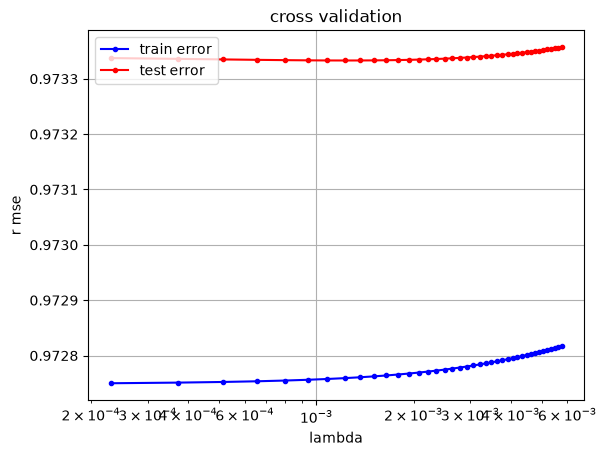

In [7]:
lambdas_fine = np.linspace(best_lambda_broad / 5, best_lambda_broad * 5, 40)
best_lambda_final, best_rmse = cross_validation_demo(4, lambdas_fine)

In [8]:
w, mse = ridge_regression(y_train, x_train_preprocessed, lambda_= best_lambda_broad)

pred_train_continuous = x_train_preprocessed @ w

# Binarize predictions for classification metrics
# Change threshold to 0.5 if your targets are in {0, 1} instead of {-1, 1}
threshold = 0.0 if np.min(y_train) < 0 else 0.5
pred_train_binary = np.where(pred_train_continuous >= threshold, 1, -1 if threshold == 0.0 else 0)

print("Scores ridge regression preprocessed data with kfold lambda:")
print(f"Accuracy:   {compute_accuracy(y_train, pred_train_binary):.4f}")
print(f"Precision:  {compute_precision(y_train, pred_train_binary):.4f}")
print(f"Recall:     {compute_recall(y_train, pred_train_binary):.4f}")
print(f"F1 Score:   {compute_f1(y_train, pred_train_binary):.4f}")
print(f"R2 Score:   {compute_r2(y_train, pred_train_continuous):.4f}")

Scores ridge regression preprocessed data with kfold lambda:
Accuracy:   0.6599
Precision:  0.1920
Recall:     0.8889
F1 Score:   0.3158
R2 Score:   -1.9390


In [9]:
pred_test_continuous = x_test_preprocessed @ w

# Convert to binary predictions matching target format
pred_test_binary = np.where(pred_test_continuous >= threshold, 1, -1 if threshold == 0.0 else 0)

# Save to results.csv using CS-433 helper function
create_csv_submission(test_ids, pred_test_binary, 'results.csv')

print("Test predictions successfully generated and saved to results.csv!")
print(f"Shape of test predictions: {pred_test_binary.shape}")

Test predictions successfully generated and saved to results.csv!
Shape of test predictions: (109379,)
